In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib widget

import os
from pathlib import Path
os.chdir(Path().cwd().parent.parent)

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from geo6.io.io import load_data
from geo6.config import Config


config = Config()

In [3]:
data = load_data()

## PCA

In [7]:
from geo6.pca import prepare_pca_data, calc_pca, plot_pca, print_pca_loadings, perform_pca

### Microresp


PCA loadings:
                        PC1       PC2       PC3
br_mg_per_g_h      0.276055 -0.191295  0.482551
sir_1_mg_per_g_h   0.323135  0.118003 -0.225308
sir_2_mg_per_g_h   0.326109 -0.064687 -0.173686
sir_3_mg_per_g_h   0.314837  0.105264 -0.270496
sir_4_mg_per_g_h   0.282041 -0.360659  0.170325
sir_5_mg_per_g_h   0.322379  0.025310 -0.193072
sir_6_mg_per_g_h   0.268764 -0.019246  0.490896
sir_7_mg_per_g_h   0.275527 -0.056066 -0.317741
sir_8_mg_per_g_h   0.307189 -0.249996  0.092748
sir_9_mg_per_g_h   0.142961  0.827175  0.199292
sir_10_mg_per_g_h  0.315394  0.053229 -0.262797
sir_11_mg_per_g_h  0.260782  0.224581  0.295702


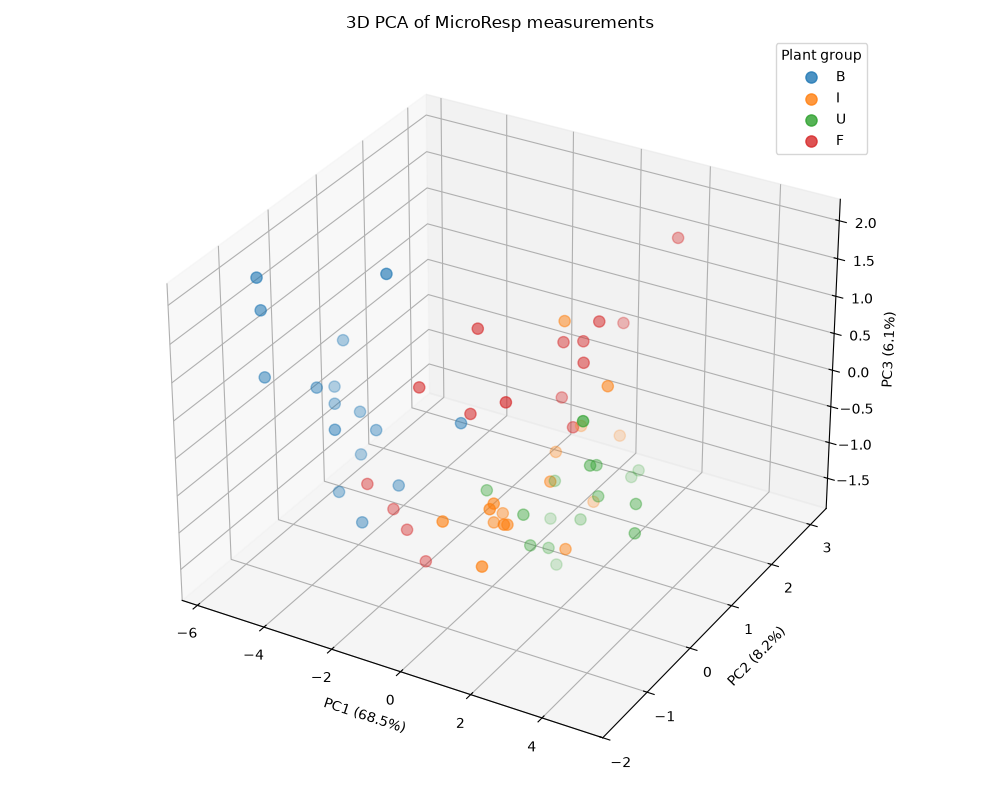

PC1    68.5%
PC2     8.2%
PC3     6.1%
dtype: str
Total variance explained by first 3 PCs: 82.9%


In [8]:
features = [
    'br_mg_per_g_h', 'sir_1_mg_per_g_h', 'sir_2_mg_per_g_h',
    'sir_3_mg_per_g_h', 'sir_4_mg_per_g_h', 'sir_5_mg_per_g_h', 
    'sir_6_mg_per_g_h', 'sir_7_mg_per_g_h', 'sir_8_mg_per_g_h',
    'sir_9_mg_per_g_h', 'sir_10_mg_per_g_h', 'sir_11_mg_per_g_h'
]

perform_pca(df=data.microresp, features=features)

## 

In [ ]:
# print(data.dissolved_carbon_nitrogen.columns)
import numpy as np

features = ['doc_inc_mg_kg', 'dic_inc_mg_kg',
       'dc_inc_mg_kg', 'dn_inc_mg_kg', 'doc_froz_mg_kg', 'dic_froz_mg_kg',
       'dc_froz_mg_kg', 'dn_froz_mg_kg', 'dcn_inc_ratio', 'dcn_froz_ratio']

df_pca, X_scaled = prepare_pca_data(df=data.dissolved_carbon_nitrogen, features=features)

corr = np.corrcoef(X_scaled, rowvar=False)
print(corr.shape)

if corr is not None:
    sns.heatmap(
       corr,
       xticklabels=features,
       yticklabels=features,
       vmin=-1,
       vmax=1,
       center=0,
       cmap="vlag",
       annot=True,
       fmt=".2f",
)
    plt.title("Correlation between MicroResp variables")
    plt.show()


(10, 10)


AttributeError: 'QuadMesh' object has no attribute 'do_3d_projection'

Index(['sample', 'type', 'group', 'subrep', 'doc_inc_mg_kg', 'dic_inc_mg_kg',
       'dc_inc_mg_kg', 'dn_inc_mg_kg', 'doc_froz_mg_kg', 'dic_froz_mg_kg',
       'dc_froz_mg_kg', 'dn_froz_mg_kg', 'dcn_inc_ratio', 'dcn_froz_ratio'],
      dtype='str')

PCA loadings:
                     PC1       PC2       PC3
doc_inc_mg_kg  -0.001051  0.507588 -0.443336
dic_inc_mg_kg   0.001958  0.031333  0.493877
dc_inc_mg_kg   -0.016856  0.513647 -0.417815
dn_inc_mg_kg    0.080165  0.518647  0.403461
doc_froz_mg_kg  0.475933 -0.024459 -0.025838
dic_froz_mg_kg  0.470428 -0.021767 -0.021143
dc_froz_mg_kg   0.476072 -0.024394 -0.025714
dn_froz_mg_kg   0.466002 -0.020208 -0.018595
dcn_inc_ratio  -0.058693 -0.451498 -0.462387
dcn_froz_ratio  0.313404 -0.051169 -0.079157


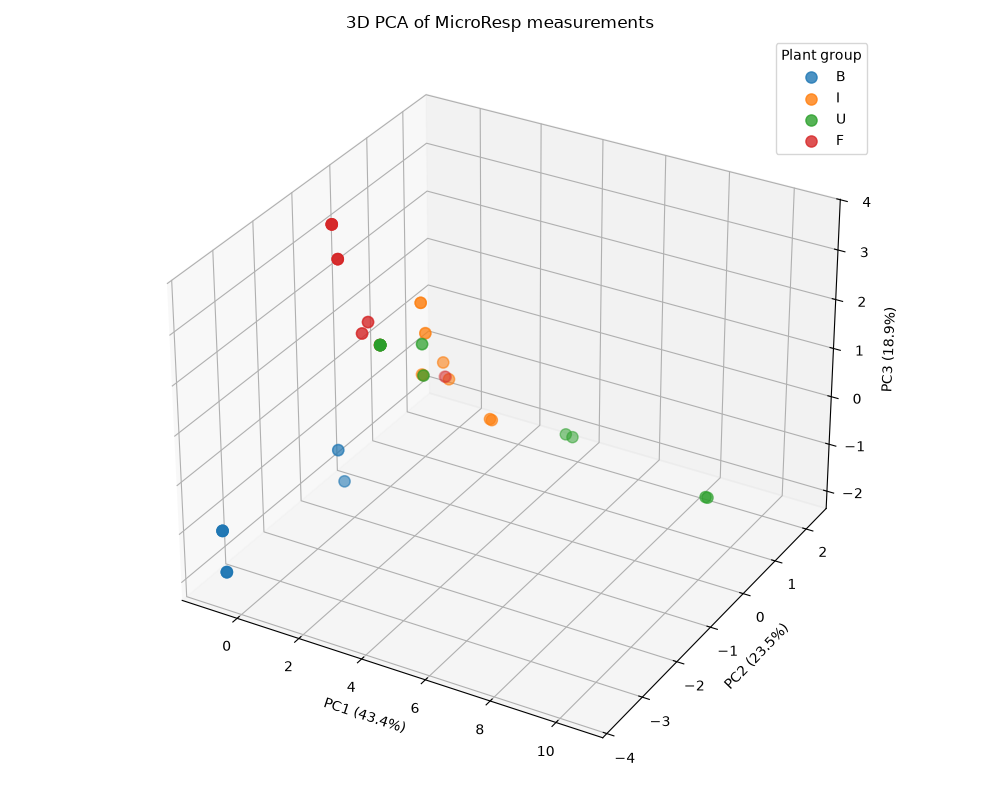

PC1    43.4%
PC2    23.5%
PC3    18.9%
dtype: str
Total variance explained by first 3 PCs: 85.8%


In [ ]:
perform_pca(df=data.dissolved_carbon_nitrogen, features=features)

### Nitrification Rate

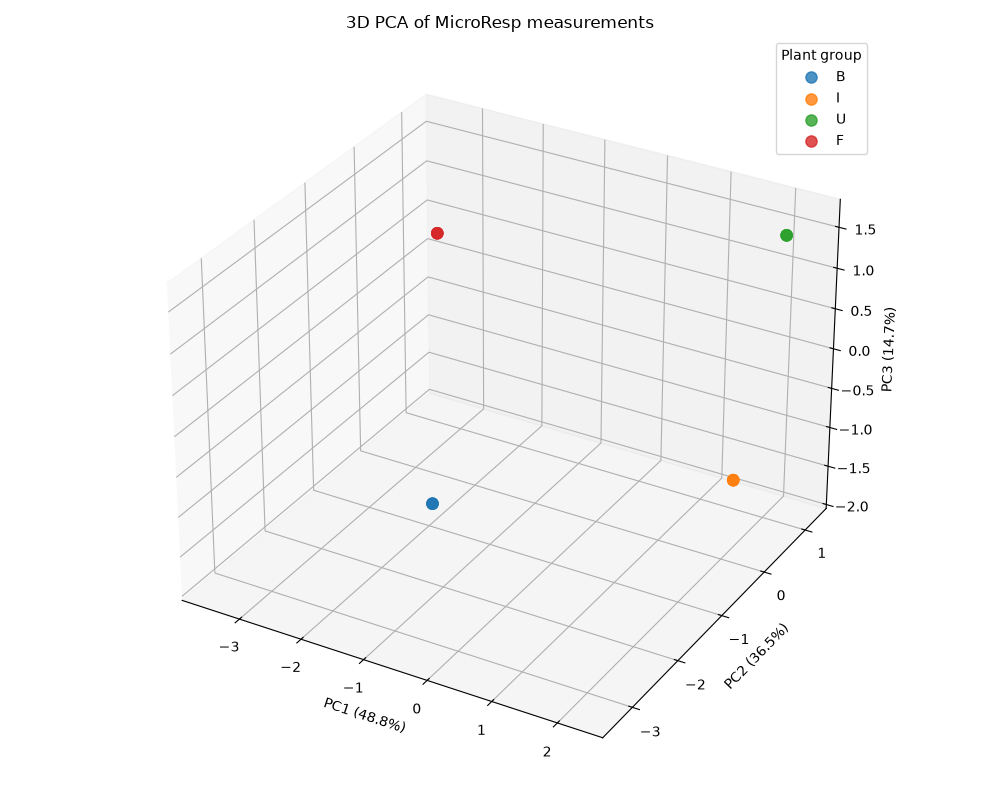

PC1    48.8%
PC2    36.5%
PC3    14.7%
dtype: str
Total variance explained by first 3 PCs: 100.0%

PCA loadings:
                           PC1       PC2       PC3
pnr_0_mg_per_kg_h_dm  0.393876  0.257577  0.029359
pnr_0_ste             0.276988  0.328640 -0.396537
pnr_W_mg_per_kg_h_dm  0.441690  0.114668 -0.022493
pnr_W_ste             0.345487  0.097708  0.510161
pnr_F_mg_per_kg_h_dm  0.428615  0.168102 -0.026680
pnr_F_ste             0.328302 -0.313466 -0.280247
pnr_I_mg_per_kg_h_dm  0.176768 -0.476520  0.111742
pnr_I_ste             0.215451 -0.282536  0.572286
pnr_U_mg_per_kg_h_dm -0.010911  0.511720  0.171141
pnr_U_ste            -0.290532  0.328146  0.364128


In [ ]:
nitrification_rate = data.nitrification_rate

# Select response vars
features = [
    # 'nitrate_n_mg_kg_dm', 'ammonium_n_mg_kg_dm', 
    'pnr_0_mg_per_kg_h_dm', 'pnr_0_ste',
    'pnr_W_mg_per_kg_h_dm', 'pnr_W_ste', 
    'pnr_F_mg_per_kg_h_dm', 'pnr_F_ste', 
    'pnr_I_mg_per_kg_h_dm', 'pnr_I_ste',
    'pnr_U_mg_per_kg_h_dm', 'pnr_U_ste'
]

df_pca, X_scaled = prepare_pca_data(df=nitrification_rate, features=features)

pca, df_scores = calc_pca(X_scaled=X_scaled, df_pca=df_pca)

plot_pca(df=df_scores, pca=pca)

print_pca_loadings(pca=pca, features=features)

## All

In [36]:
data.cation_exchange_capacity.columns

Index(['sample', 'type', 'subrep', 'group', 'cec_pot_cmolc_kg',
       'cec_eff_cmolc_kg'],
      dtype='str')

In [58]:
from functools import reduce
from dataclasses import fields

field_names = [field.name for field in fields(data)]
dfs = [getattr(data, name) for name in field_names]

keys = ['sample', 'type', 'subrep', 'group']

df_merged = reduce(
    lambda left, right: pd.merge(
        left,
        right,
        on=keys,
        how="outer",
        validate="one_to_one",
    ),
    dfs,
)

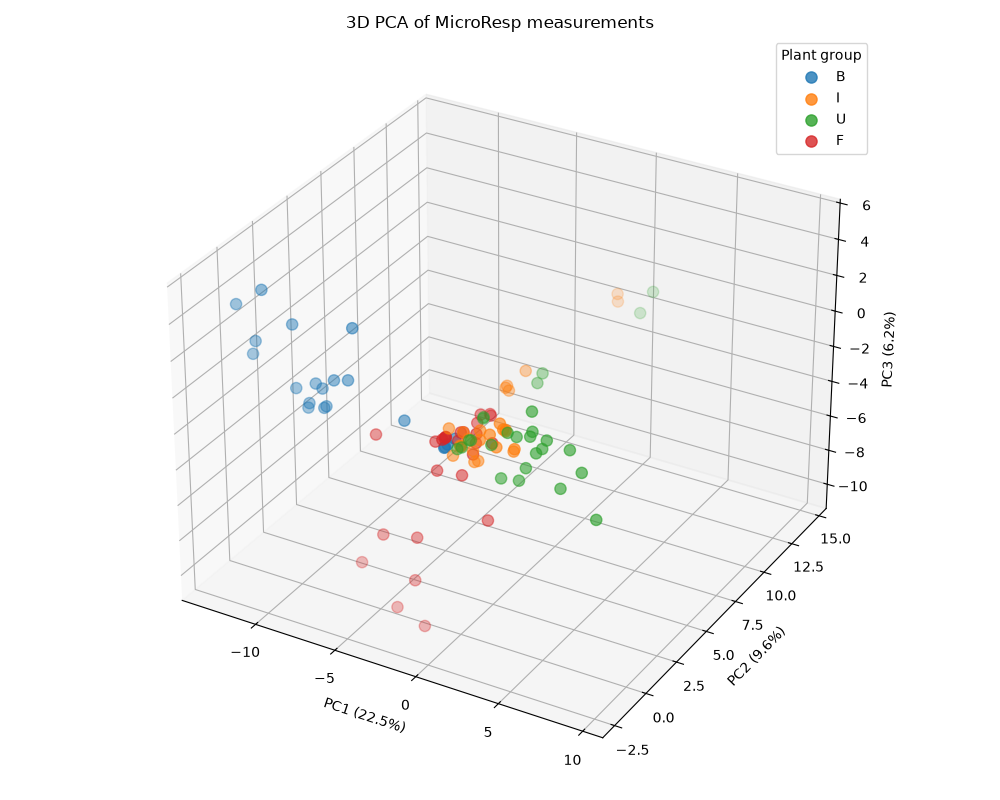

PC1    22.5%
PC2     9.6%
PC3     6.2%
dtype: str
Total variance explained by first 3 PCs: 38.2%

PCA loadings:
                          PC1       PC2       PC3
sand_percent         0.039541 -0.037702 -0.179874
silt_percent        -0.031822  0.033618  0.135680
clay_percent        -0.018065 -0.007619  0.080925
humus_percent        0.004826 -0.027039  0.150327
cec_pot_cmolc_kg    -0.009858  0.011962  0.212466
...                       ...       ...       ...
br_U2_mg_per_g_h     0.175978 -0.003436  0.062782
br_F2_mg_per_g_h     0.171298 -0.004739  0.042885
sir_1_I2_mg_per_g_h  0.194297  0.003526  0.049115
sir_1_U2_mg_per_g_h  0.190731 -0.007523  0.064505
sir_1_F2_mg_per_g_h  0.193049  0.002697  0.049276

[93 rows x 3 columns]


In [62]:
# Select response vars
features = df_merged.drop(columns=['sample', 'type', 'subrep', 'group']).columns.to_list()

df_pca, X_scaled = prepare_pca_data(df=df_merged, features=features)

pca, df_scores = calc_pca(X_scaled=X_scaled, df_pca=df_pca)

plot_pca(df=df_scores, pca=pca)

print_pca_loadings(pca=pca, features=features)

In [64]:
import plotly.graph_objects as go

# Sample scores
scores = df_scores.copy()

# PCA loadings
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=["PC1", "PC2", "PC3"],
)

fig = go.Figure()

# Plot samples, colored by plant group
for group in scores["sample"].unique():
    subset = scores[scores["sample"] == group]

    fig.add_trace(go.Scatter3d(
        x=subset["PC1"],
        y=subset["PC2"],
        z=subset["PC3"],
        mode="markers",
        name=f"Group {group}",
        marker=dict(size=5),
    ))

# Scale loading vectors for visibility alongside sample scores
scale = scores[["PC1", "PC2", "PC3"]].abs().max().max()

for parameter, row in loadings.iterrows():
    x, y, z = row[["PC1", "PC2", "PC3"]] * scale

    fig.add_trace(go.Scatter3d(
        x=[0, x],
        y=[0, y],
        z=[0, z],
        mode="lines+text",
        name=parameter,
        text=["", parameter],
        textposition="top center",
        line=dict(width=4),
        showlegend=False,
        hovertemplate=f"{parameter}<extra></extra>",
    ))

fig.update_layout(
    title="3D PCA biplot: MicroResp measurements",
    scene=dict(
        xaxis_title=f"PC1 ({pca.explained_variance_ratio_[0]:.1%})",
        yaxis_title=f"PC2 ({pca.explained_variance_ratio_[1]:.1%})",
        zaxis_title=f"PC3 ({pca.explained_variance_ratio_[2]:.1%})",
    ),
    legend_title="Plant group",
)

fig.show()

In [67]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots


# PCA loadings
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=["PC1", "PC2", "PC3"],
)

# The three PC combinations
pc_pairs = [
    ("PC1", "PC2"),
    ("PC1", "PC3"),
    ("PC2", "PC3"),
]

# Scale arrows for visibility alongside sample scores
score_max = df_scores[["PC1", "PC2", "PC3"]].abs().max().max()
loading_max = loadings.abs().to_numpy().max()
arrow_scale = score_max / loading_max * 0.7

for pc_x, pc_y in pc_pairs:
    fig = go.Figure()

    # Plot samples, colored by plant group
    for group in df_scores["sample"].unique():
        subset = df_scores[df_scores["sample"] == group]

        fig.add_trace(go.Scatter(
            x=subset[pc_x],
            y=subset[pc_y],
            mode="markers",
            name=f"Group {group}",
            marker=dict(size=8, opacity=0.8),
            hovertemplate=(
                f"Group: {group}<br>"
                f"{pc_x}: %{{x:.2f}}<br>"
                f"{pc_y}: %{{y:.2f}}"
                "<extra></extra>"
            ),
        ))

    # Plot parameter loading arrows
    for parameter, row in loadings.iterrows():
        x = row[pc_x] * arrow_scale
        y = row[pc_y] * arrow_scale

        # Draw arrow from origin to loading position
        fig.add_annotation(
            x=x,
            y=y,
            ax=0,
            ay=0,
            xref="x",
            yref="y",
            axref="x",
            ayref="y",
            showarrow=True,
            arrowhead=2,
            arrowsize=1,
            arrowwidth=1.5,
        )

        # Place feature name at the arrow tip
        fig.add_trace(go.Scatter(
            x=[x],
            y=[y],
            mode="text",
            text=[parameter],
            textposition="top center",
            textfont=dict(size=10),
            showlegend=False,
            hoverinfo="skip",
        ))

    # Axis labels include explained variance
    x_idx = int(pc_x[-1]) - 1
    y_idx = int(pc_y[-1]) - 1

    fig.update_layout(
        title=f"PCA biplot: {pc_x} vs. {pc_y}",
        xaxis_title=(
            f"{pc_x} "
            f"({pca.explained_variance_ratio_[x_idx]:.1%} variance)"
        ),
        yaxis_title=(
            f"{pc_y} "
            f"({pca.explained_variance_ratio_[y_idx]:.1%} variance)"
        ),
        template="plotly_white",
        width=1000,
        height=750,
        hovermode="closest",
    )

    # Equal axis scaling makes arrow directions easier to compare
    fig.update_yaxes(scaleanchor="x", scaleratio=1)

    fig.show()

## Else

In [9]:
copper = data.copper
copper_sub = copper[["sample", "cu_ex_ug_kg_dm", "cu_org_ug_kg_dm", "cu_red_ug_kg_dm"]]


copper_agg = (
    copper_sub
    .groupby("sample")
    .agg(
        ["mean", "std"]
    )
    .reset_index()
)

C:\Users\Administrator\AppData\Local\Temp\ipykernel_6104\2136735052.py:1: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  data_cols = copper_agg.drop(columns="sample").columns.to_list()


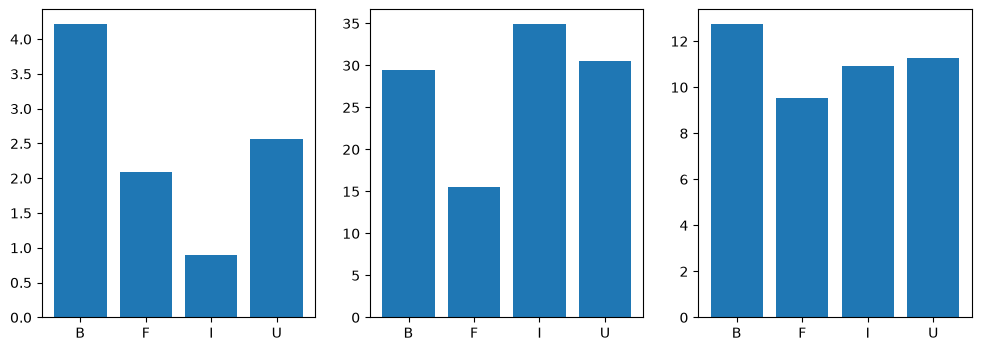

In [40]:
data_cols = copper_agg.drop(columns="sample").columns.to_list()

mean_cols = [col[0] for col in data_cols if col[1] == "mean"]
std_cols = [col[0] for col in data_cols if col[1] == "std"]


fig, axs = plt.subplots(figsize=(12, 4), ncols=3)

for i, col in enumerate(mean_cols):
    
    axs[i].bar(
        x=copper_agg["sample"],
        height=copper_agg[col]["mean"]
    )